## MuJoCo 3DoF USV

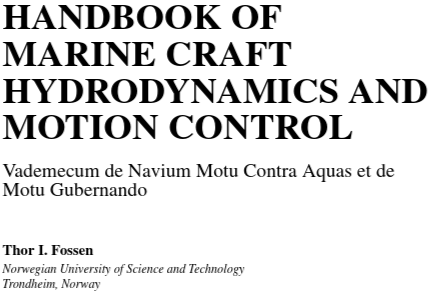

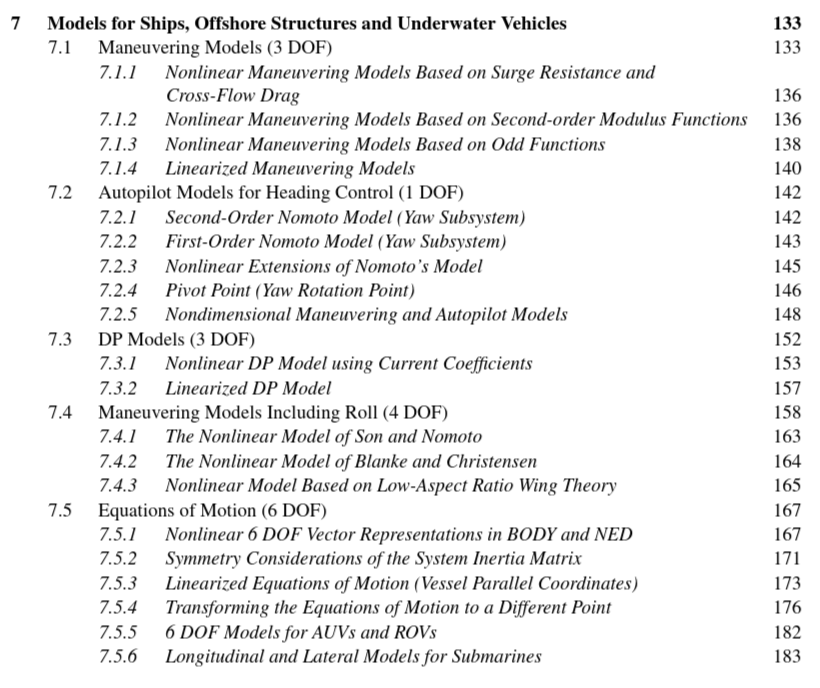

In [1]:
from IPython.display import clear_output

!pip install --upgrade jupyter_client
!pip install dm_control==1.0.41 mujoco==3.8.1 mediapy stable-baselines3

clear_output()

In [2]:
import os
import subprocess
try:
  subprocess.run('nvidia-smi')
  use_GPU = True

except:
  use_GPU = False


if use_GPU:
  NVIDIA_ICD_CONFIG_PATH = '/usr/share/glvnd/egl_vendor.d/10_nvidia.json'
  if not os.path.exists(NVIDIA_ICD_CONFIG_PATH):
    with open(NVIDIA_ICD_CONFIG_PATH, 'w') as f:
      f.write("""{
      "file_format_version" : "1.0.0",
      "ICD" : {
          "library_path" : "libEGL_nvidia.so.0"
      }
  }
  """)
  %env MUJOCO_GL=egl

env: MUJOCO_GL=egl


In [3]:
from IPython.display import display, update_display

from matplotlib import pyplot as plt
from matplotlib.patches import Circle

from gymnasium import spaces
import gymnasium as gym

from dm_control import mjcf

import mediapy as media
import numpy as np
import os

In [4]:
from stable_baselines3.common.vec_env import DummyVecEnv, VecNormalize, SubprocVecEnv
from stable_baselines3.common.callbacks import BaseCallback
from stable_baselines3.common.env_util import make_vec_env
from stable_baselines3.common.env_checker import check_env
from stable_baselines3.common.monitor import Monitor

from stable_baselines3 import PPO, SAC

Gym has been unmaintained since 2022 and does not support NumPy 2.0 amongst other critical functionality.
Please upgrade to Gymnasium, the maintained drop-in replacement of Gym, or contact the authors of your software and request that they upgrade.
See the migration guide at https://gymnasium.farama.org/introduction/migration_guide/ for additional information.


In [5]:
def make_boat(model, pos=[0, 0]):

  model.asset.add('mesh', name='Hull', file='Hull.stl')
  model.asset.add('mesh', name='Rudder', file='Rudder.stl')

  boat = model.worldbody.add('body', name='Boat', pos=np.hstack([pos, [0.2]]))
  boat.add('geom', type='mesh', mesh='Hull', fluidshape='ellipsoid')
  boat.add('joint', name='x', type='slide', axis=[1, 0, 0])
  boat.add('joint', name='y', type='slide', axis=[0, 1, 0])
  boat.add('joint', name='z', type='hinge', axis=[0, 0, 1])
  boat.add('camera', name='cam', pos=[0,-0.5, 0.2], mode='targetbody', target='Boat')
  #boat.add('site', name='motor', pos=[-0.0009308310250129816, -0.185, -0.015])

  #model.actuator.add('motor', name='Motor Actuator', site='motor', gear=[0, 1, 0, 0, 0, 0], ctrlrange=[-5, 5])

  rudder = boat.add('body', name='Rudder', pos=[-0.029536, -0.251494, 0.033548])
  rudder.add('geom', type='mesh', mesh='Rudder')
  rudder.add('joint', name='Rudder Joint', type='hinge', axis=[0, 0, 1], range=[-90, 90])
  rudder.add('site', name='motor', pos=[0, -0.027, -0.04]) # New

  model.actuator.add('motor', name='Motor Actuator', site='motor', gear=[0, 1, 0, 0, 0, 0], ctrlrange=[-1, 1]) # New
                                                                              #kp=0.001
  model.actuator.add('position', name='Rudder Actuator', joint='Rudder Joint', kp=0.01, kv=0.0001, ctrlrange=np.deg2rad([-90, 90]))

  return model

In [6]:
def make_model():
  model = mjcf.RootElement()

  chequered_texture = model.asset.add('texture', type='2d', builtin='checker', width=300, height=300,
                                      rgb1=[.2, .3, .4], rgb2=[.3, .4, .5])

  grid_material = model.asset.add('material', name='Grid', texture = chequered_texture, texrepeat=[50, 50], reflectance=.2)

  model.option.density = 1000
  model.option.viscosity = 0.0009

  model.worldbody.add('light', directional=True, diffuse=[.9, .9, .9], specular=[.1, .1, .1], pos=[0, 0, 5], dir=[0, 0, -1], castshadow=True)

  model.worldbody.add('geom', type='plane', size=[0, 0, .1], material=grid_material)
  model.worldbody.add('geom', type='sphere', size=[1], contype=0, conaffinity=0, rgba=[1, 0, 0, 0.25])

  make_boat(model)

  return model

### [Using Custom Environments](https://stable-baselines3.readthedocs.io/en/master/guide/custom_env.html)

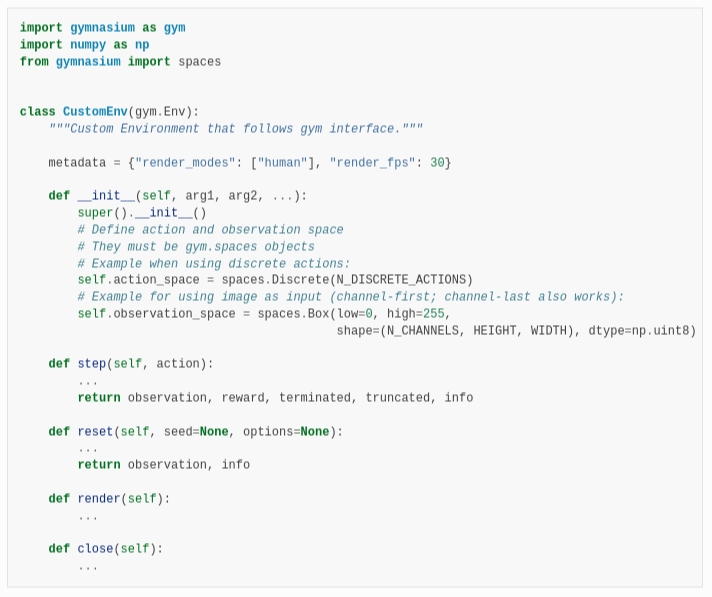

In [7]:
class NavigationEnv(gym.Env):
    metadata = {'render_modes': ['rgb_array']}

    def __init__(self, max_time=90, render_mode='rgb_array'):
        super().__init__()

        model = make_model()
        self.physics = mjcf.Physics.from_mjcf_model(model)
        self.max_time = max_time
        self.render_mode = render_mode

        self.action_space = spaces.Box(low=-1, high=1, shape=[2], dtype=np.float32)
        self.observation_space = spaces.Box(low=-np.inf, high=np.inf, shape=[10], dtype=np.float32)

        self.prev_dist = 0.0

    def reset(self, seed=None, options=None):
        super().reset(seed=seed, options=options)

        self.physics.reset()

        rand_pos = np.random.uniform(-10, 10, 2)
        while np.linalg.norm(rand_pos) < 1:
          rand_pos = np.random.uniform(-10, 10, 2)

        rand_yaw = np.random.uniform(-np.pi, np.pi)


        self.physics.named.data.qpos['x'] = rand_pos[0]
        self.physics.named.data.qpos['y'] = rand_pos[1]
        self.physics.named.data.qpos['z'] = rand_yaw
        self.physics.named.data.qpos['Rudder Joint'] = 0.0

        self.physics.forward()

        self.prev_dist = np.linalg.norm(self.physics.named.data.xipos['Boat'][:2])

        info = {}

        return self.get_state(), info

    def get_state(self):

      boat_pos = self.physics.named.data.xipos['Boat'][:2] # [x, y]
      boat_vel = self.physics.named.data.cvel['Boat'][2:5] # [rot_vel z, lin_vel x, lin_vel y]

      target_pos = np.array([0.0, 0.0])
      relative_pos = target_pos - boat_pos

      yaw = self.physics.named.data.qpos['z'][0]
      rudder_angle = self.physics.named.data.qpos['Rudder Joint'][0]

      prev_action = self.physics.data.ctrl.copy()

      state = np.hstack([
          relative_pos,
          np.sin(yaw),
          np.cos(yaw),
          boat_vel,
          rudder_angle,
          prev_action
      ]).astype(np.float32)

      return state

    def get_reward(self, state):
      current_dist = np.linalg.norm(state[:2])

      progress_reward = (self.prev_dist - current_dist) * 10.0

      self.prev_dist = current_dist

      time_penalty = -0.1

      reward = progress_reward + time_penalty

      if self.get_is_terminal(state):
        reward += 100

      return reward

    def get_is_terminal(self, state):
      current_dist = np.linalg.norm(state[:2])
      boat_speed = np.linalg.norm(state[5:7])

      is_terminal = np.bitwise_and((current_dist < 1), (boat_speed < 0.5)).item()

      return is_terminal


    def step(self, action=[0, 0]):

        # Transform actions range (-1, 1) to control range
        motor_force = action[0]
        if action[0] > 0:
          motor_force *= 5 #Approximation
        else:
          motor_force = 0

        self.physics.named.data.ctrl['Motor Actuator'] = motor_force
        self.physics.named.data.ctrl['Rudder Actuator'] = action[1] * np.deg2rad(90)

        for _ in range(25):
            self.physics.step()

        state = self.get_state()
        reward = self.get_reward(state)
        is_terminal = self.get_is_terminal(state)
        is_truncated = self.physics.data.time > self.max_time
        info = {}

        return state, reward, is_terminal, is_truncated, info

    def render(self, height=480, width=640, camera_id='cam'):
        if self.render_mode == 'rgb_array':
            return self.physics.render(height=height, width=width, camera_id=camera_id)

    def get_time(self):
        return self.physics.data.time

In [8]:
env = NavigationEnv()
check_env(env)

In [9]:
class ColabEpisodePlotter(BaseCallback):
    def __init__(self, check_freq_episodes: int, window_size: int = 10):
        """
        Args:
            check_freq_episodes: How many episodes should complete before updating the plot.
            window_size: Moving average window size to smooth the trend line.
        """
        super().__init__()
        self.check_freq_episodes = check_freq_episodes
        self.window_size = window_size

        # Track metrics internally
        self.episode_rewards = []
        self.episode_count = 0

        # Colab display configuration
        self.display_id = "colab_episode_live_plot"
        self.initialized = False

    def _on_step(self) -> bool:
        # Stable-baselines3 vectorized environments can run multiple parallel envs.
        # We loop through the info dicts of the current step to catch finished episodes.
        for info in self.locals.get("infos", []):
            if "episode" in info.keys():
                self.episode_count += 1
                self.episode_rewards.append(info["episode"]["r"]) # 'r' is the total episodic reward

                # Check if it's time to refresh the plot layout
                if self.episode_count % self.check_freq_episodes == 0:
                    self._update_plot()

        return True

    def _update_plot(self):
        episodes = np.arange(1, len(self.episode_rewards) + 1)
        rewards = np.array(self.episode_rewards)

        # Render the chart silently in the background
        fig, ax = plt.subplots(figsize=(8.5, 4.5))
        ax.plot(episodes, rewards, label="Raw Episode Reward", color="mediumpurple", alpha=0.4)

        # Apply a rolling window mean for smoothing out trend shifts
        if len(rewards) >= self.window_size:
            smooth_rewards = np.convolve(rewards, np.ones(self.window_size)/self.window_size, mode='valid')
            ax.plot(episodes[self.window_size-1:], smooth_rewards, label=f"Moving Avg (Last {self.window_size} Eps)", color="darkorchid", linewidth=2.5)

            # Print latest average in the title
            latest_avg = smooth_rewards[-1]
            ax.set_title(f"Training Progress — {self.episode_count} Episodes (Current Avg Reward: {latest_avg:.2f})", fontsize=11, fontweight='bold')
        else:
            ax.set_title(f"Training Progress — {self.episode_count} Episodes", fontsize=11, fontweight='bold')

        ax.set_xlabel("Completed Episodes")
        ax.set_ylabel("Total Reward per Episode")
        ax.legend(loc="upper left")
        ax.grid(True, linestyle="--", alpha=0.5)
        plt.tight_layout()

        # Update the placeholder container smoothly in the notebook
        if not self.initialized:
            display(fig, display_id=self.display_id)
            self.initialized = True
        else:
            update_display(fig, display_id=self.display_id)

        plt.close(fig) # Clear memory references instantly

### PPO

In [10]:
def load_PPO_agent(log_dir, vec_normalize_file, model_weights_file, n_envs=2):
  vec_path = os.path.join(log_dir, vec_normalize_file)
  model_path = os.path.join(log_dir, model_weights_file)

  if os.path.isfile(vec_path) and os.path.isfile(model_path):

    env = make_vec_env(NavigationEnv, n_envs=n_envs, vec_env_cls=SubprocVecEnv)
    env = VecNormalize.load(vec_path, env)
    env.training = True
    env.norm_obs  = True
    env.norm_reward = False
    env.clip_obs = 10.0

    agent = PPO.load(model_path, env=env)

  else:
    os.makedirs(log_dir, exist_ok=True)

    env = make_vec_env(NavigationEnv, n_envs=2, vec_env_cls=SubprocVecEnv)
    env = VecNormalize(env, norm_obs=True, norm_reward=False, clip_obs=10.0)

    agent = PPO("MlpPolicy", env, verbose=0,
                learning_rate=3e-4,
                n_steps=4096,
                batch_size=512,
                clip_range=0.2,
                ent_coef=0.01,
                vf_coef=0.5)

  return agent, env


Output()

/usr/local/lib/python3.12/dist-packages/ipywidgets/widgets/widget_output.py:111: DeprecationWarning: 
Kernel._parent_header is deprecated in ipykernel 6. Use .get_parent()
  if ip and hasattr(ip, 'kernel') and hasattr(ip.kernel, '_parent_header'):

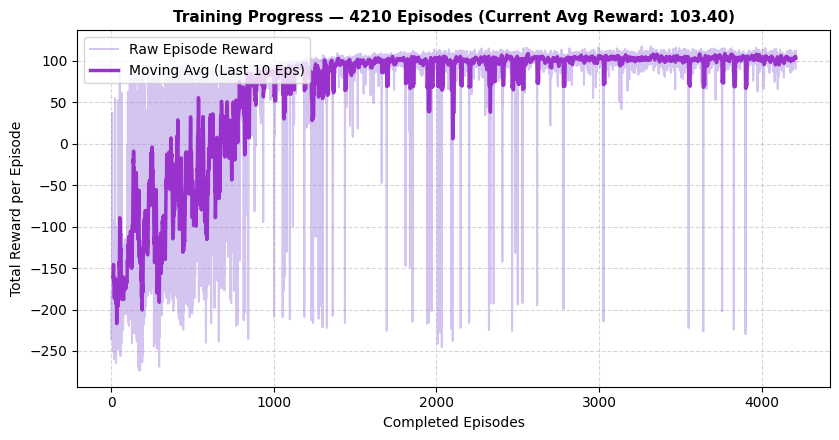


Training complete!
CPU times: user 35min 58s, sys: 1min 29s, total: 37min 27s
Wall time: 1h 14min 9s


In [ ]:
%%time

log_dir = "colab_ppo_log"
vec_normalize_file = "vec_normalize.pkl"
model_weights_file = "ppo_boat.zip"

agent, env = load_PPO_agent(log_dir, vec_normalize_file, model_weights_file)

episode_callback = ColabEpisodePlotter(check_freq_episodes=5, window_size=10)

agent.learn(total_timesteps=3_500_000,
            callback=episode_callback,
            reset_num_timesteps=False,
            progress_bar=True)
print("\nTraining complete!")


env.save(os.path.join(log_dir, vec_normalize_file))
agent.save(os.path.join(log_dir, model_weights_file))

env.close()

In [19]:
framerate = 30  # (Hz)

height = 480
width = 640

frames = []

log_dir = "colab_ppo_log"
vec_normalize_file = "vec_normalize.pkl"
model_weights_file = "ppo_boat.zip"

agent, deploy_env = load_PPO_agent(log_dir, vec_normalize_file, model_weights_file, n_envs=1)

deploy_env.train = False
state = deploy_env.reset()
is_done = False

frame_idx = 0
positions = []
while not is_done:

  action, _states = agent.predict(state, deterministic=True)
  state, reward, is_terminal, info = deploy_env.step(action)

  is_done = is_terminal[0]

  current_time = deploy_env.env_method('get_time', indices=0)[0]
  if frame_idx < current_time * framerate:
    frame = deploy_env.render()
    frames.append(frame)

    pos = deploy_env.env_method('get_state', indices=0)[0]
    positions.append(pos)

    frame_idx += 1

media.show_video(frames, fps=framerate)

This browser does not support the video tag.


In [ ]:
media.write_video('Lanchita.mp4', frames, fps=framerate)

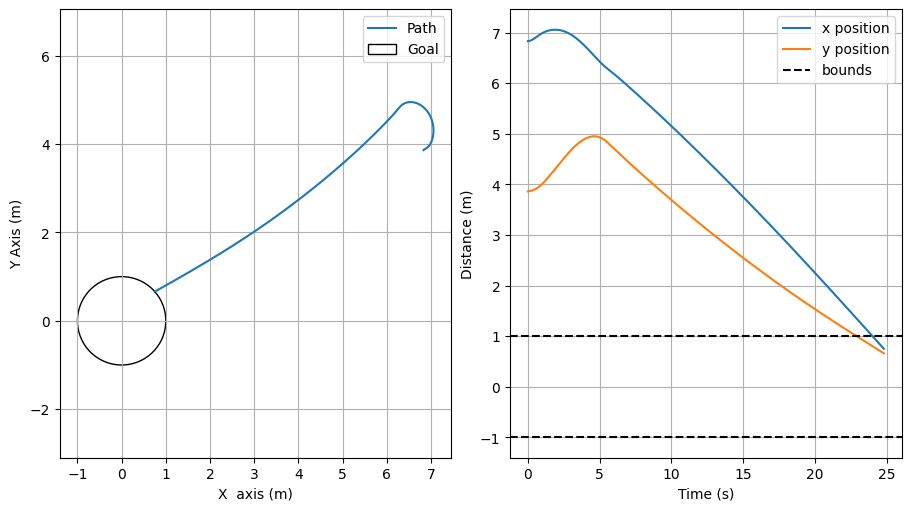

In [20]:
positions = np.array(positions)
time = np.arange(0, len(positions)/framerate, 1/framerate)

fig, ax = plt.subplots(1, 2, layout='constrained', figsize=(9,5))
ax[0].plot(positions[:, 0], positions[:, 1], label='Path')
circle = Circle((0,0), 1, edgecolor='black', facecolor='none', label='Goal')
ax[0].add_patch(circle)
ax[0].set(xlabel='X  axis (m)', ylabel=r'Y Axis (m)')
ax[0].axis('equal')
ax[0].legend()
ax[0].grid()

ax[1].plot(time, positions[:, 0], label='x position')
ax[1].plot(time, positions[:, 1], label='y position')
ax[1].axhline(1, linestyle='--', color='black', label='bounds')
ax[1].axhline(-1, linestyle='--', color='black')
ax[1].set(xlabel='Time (s)', ylabel='Distance (m)')

ax[1].legend()
ax[1].grid()

plt.show()

### SAC

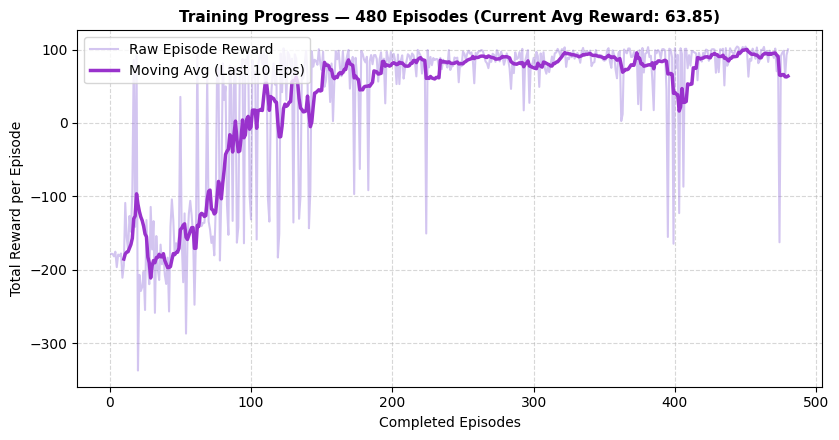


Training complete!
CPU times: user 3h 40min 11s, sys: 7.44 s, total: 3h 40min 18s
Wall time: 3h 41min 44s


In [ ]:
%%time

log_dir = "./colab_sac_log/"
os.makedirs(log_dir, exist_ok=True)

env = make_vec_env(NavigationEnv, n_envs=1, vec_env_cls=DummyVecEnv)

env = VecNormalize(env, norm_obs=True, norm_reward=False, clip_obs=10.0)

episode_callback = ColabEpisodePlotter(check_freq_episodes=5, window_size=10)

agent = SAC("MlpPolicy",env,
    learning_rate=3e-4,
    buffer_size=1_000_000,
    learning_starts=10_000,
    batch_size=256,
    tau=0.005,
    gamma=0.99,
    ent_coef="auto",
    train_freq=64,
    gradient_steps=64)

agent.learn(total_timesteps=500_000, callback=episode_callback)
print("\nTraining complete!")

env.save(os.path.join(log_dir, "vec_normalize.pkl"))
agent.save(os.path.join(log_dir, "sac_boat"))
